# Credit Card Fraud Detection: Autoencoder vs KNN

**Goal:** predict whether a credit card transaction is fraudulent.

**Main metric:** AUPRC (Area Under the Precision-Recall Curve). Only 0.17% of transactions are fraud, so accuracy is not meaningful.

**Contents**
1. Setup and data loading
2. Exploratory data analysis
3. Preprocessing
4. Autoencoder (Early Stopping + Keras Tuner)
5. KNN (elbow method)
6. Comparison and conclusion

## 1. Setup and data loading

In [1]:
!pip install -q keras-tuner

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
import keras_tuner as kt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

In [3]:
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
df = pd.read_csv(path + "/creditcard.csv")
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


The data is downloaded from Kaggle with `kagglehub`.

Columns: `V1`–`V28` are PCA components, `Time` is seconds since the first transaction, `Amount` is the transaction amount, and `Class` is the label (1 = fraud).

## 2. Exploratory data analysis

In [4]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Time span (hours):", round(df["Time"].max() / 3600, 1))
print()
print(df["Class"].value_counts())
print(f"Fraud percentage: {df['Class'].mean() * 100:.3f}%")

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081
Time span (hours): 48.0

Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.173%


**Insights**
- No missing values, but there are duplicate rows (removed later, so the same row cannot appear in both train and test).
- Extreme imbalance: only 492 frauds out of 284,807 transactions (0.17%). A model that always predicts "normal" would be 99.8% accurate and useless.
- The data covers only 2 days, so `Time` cannot show a reliable pattern. We drop it.

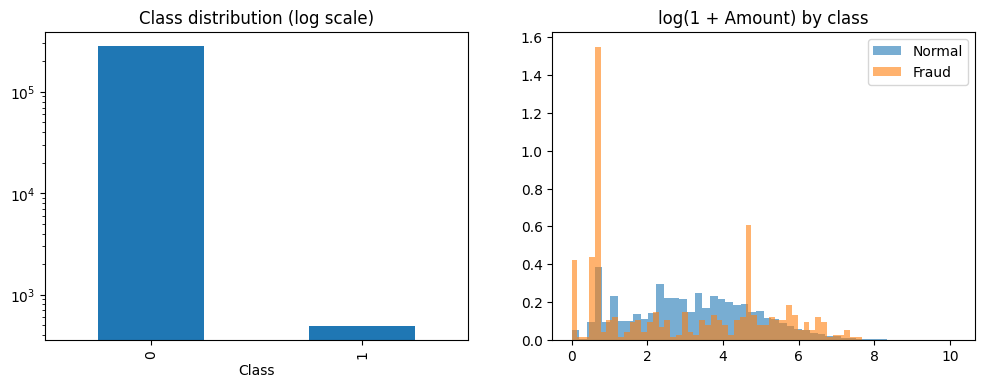

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df["Class"].value_counts().plot(kind="bar", ax=ax[0], logy=True)
ax[0].set_title("Class distribution (log scale)")

ax[1].hist(np.log1p(df[df.Class == 0]["Amount"]), bins=50, alpha=0.6, density=True, label="Normal")
ax[1].hist(np.log1p(df[df.Class == 1]["Amount"]), bins=50, alpha=0.6, density=True, label="Fraud")
ax[1].set_title("log(1 + Amount) by class")
ax[1].legend()
plt.show()

print(df.groupby("Class")["Amount"].describe().round(2))

**Insights**
- `Amount` is highly skewed (median 22, mean 88, max 25,691), so we apply `log1p` to it.
- Fraud transactions tend to have smaller amounts: the median fraud amount is 9.25 vs 22 for normal transactions.
- Amount alone cannot separate the classes, since the two distributions overlap heavily.

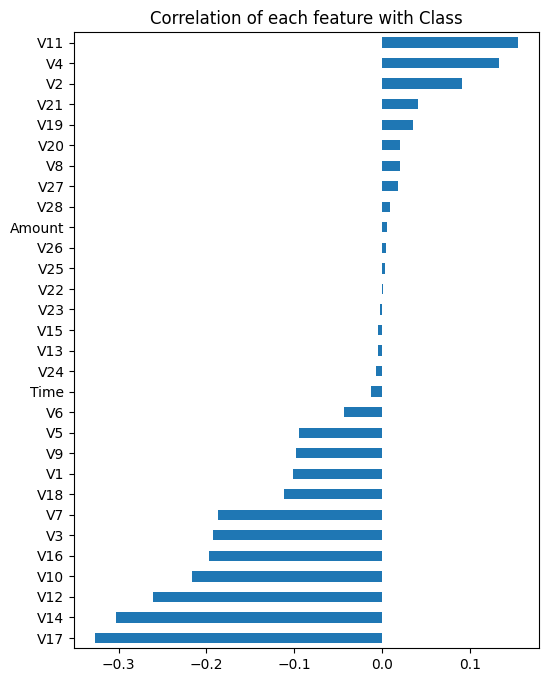

In [6]:
corr = df.corr()["Class"].drop("Class").sort_values()
corr.plot(kind="barh", figsize=(6, 8), title="Correlation of each feature with Class")
plt.show()

**Insights**
- The strongest signals are `V17`, `V14`, `V12` and `V10` (all negatively correlated with fraud).
- All correlations are weak (below 0.35), so fraud is not explained by a single feature. Models need to combine many features.

## 3. Preprocessing

- Remove duplicates, apply `log1p` to `Amount`, drop `Time`.
- Stratified split: 60% train, 20% validation, 20% test (same fraud ratio in each part).
- Scale the features with `StandardScaler` (fitted on the training set only).

In [7]:
data = df.drop_duplicates().copy()
data["Amount"] = np.log1p(data["Amount"])

X = data.drop(columns=["Time", "Class"])
y = data["Class"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, "| frauds:", y_train.sum())
print("Val:  ", X_val.shape, "| frauds:", y_val.sum())
print("Test: ", X_test.shape, "| frauds:", y_test.sum())

Train: (170235, 29) | frauds: 284
Val:   (56745, 29) | frauds: 94
Test:  (56746, 29) | frauds: 95


The test set has very few frauds, so small differences between models should be read with care.

## 4. Autoencoder

**Idea:** the autoencoder is trained on **normal transactions only**, so it learns to rebuild normal behavior. A fraud looks different, so it is rebuilt badly (high reconstruction error). The reconstruction error is the fraud score.

**Regularization:** Early Stopping (stops training when the validation loss stops improving and restores the best weights).

In [8]:
X_train_normal = X_train[y_train == 0]
X_val_normal = X_val[y_val == 0]

### 4.1 Hyperparameter tuning (Keras Tuner)

In [9]:
def build_model(hp):
    units = hp.Choice("units", [16, 32, 64])
    bottleneck = hp.Choice("bottleneck", [8, 12, 16])
    lr = hp.Choice("learning_rate", [0.01, 0.003, 0.001])

    inputs = keras.layers.Input(shape=(X_train.shape[1],))
    x = keras.layers.Dense(units, activation="relu")(inputs)
    x = keras.layers.Dense(bottleneck, activation="relu")(x)
    x = keras.layers.Dense(units, activation="relu")(x)
    outputs = keras.layers.Dense(X_train.shape[1])(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

The model compresses the 29 features into a small `bottleneck` layer and then rebuilds them. Keras Tuner tries different values for the number of units, the bottleneck size and the learning rate, and keeps the model with the lowest validation loss.

In [10]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

tuner = kt.RandomSearch(
    build_model,
    objective="val_loss",
    max_trials=10,
    overwrite=True,
    directory="my_tuning",
    project_name="fraud_autoencoder"
)

tuner.search(X_train_normal, X_train_normal,
             epochs=50, batch_size=512,
             validation_data=(X_val_normal, X_val_normal),
             callbacks=[early_stop])

Trial 10 Complete [00h 01m 09s]
val_loss: 0.057723041623830795

Best val_loss So Far: 0.016824621707201004
Total elapsed time: 00h 10m 02s


### 4.2 Best hyperparameters

In [11]:
best_hp = tuner.get_best_hyperparameters(1)[0]

print("Best hyperparameters:")
print("  units:", best_hp.get("units"))
print("  bottleneck:", best_hp.get("bottleneck"))
print("  learning_rate:", best_hp.get("learning_rate"))

best_model = tuner.get_best_models(1)[0]
print("\nBest validation loss (MSE):", round(best_model.evaluate(X_val_normal, X_val_normal, verbose=0), 4))

Best hyperparameters:
  units: 64
  bottleneck: 16
  learning_rate: 0.003


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



Best validation loss (MSE): 0.0168


These are the best settings found by the search, and the validation loss they achieved. `best_model` is the trained model from the best trial.

### 4.3 Evaluation on the test set

In [12]:
def evaluate(val_scores, test_scores):
    prec, rec, thr = precision_recall_curve(y_val, val_scores)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    threshold = thr[np.argmax(f1[:-1])]
    y_pred = (test_scores >= threshold).astype(int)

    results = {
        "AUPRC": average_precision_score(y_test, test_scores),
        "ROC-AUC": roc_auc_score(y_test, test_scores),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    }
    for name, value in results.items():
        print(f"{name}: {value:.4f}")

    print("\nConfusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, y_pred))
    return results

Both models give each transaction a fraud score. This function picks the score threshold with the best F1 on the **validation** set, applies it to the **test** set, and prints the metrics.

In [13]:
val_scores = np.mean((X_val - best_model.predict(X_val, verbose=0)) ** 2, axis=1)
test_scores = np.mean((X_test - best_model.predict(X_test, verbose=0)) ** 2, axis=1)

ae_results = evaluate(val_scores, test_scores)

AUPRC: 0.6001
ROC-AUC: 0.9449
Precision: 0.6353
Recall: 0.5684
F1: 0.6000

Confusion matrix (rows = actual, columns = predicted):
[[56620    31]
 [   41    54]]


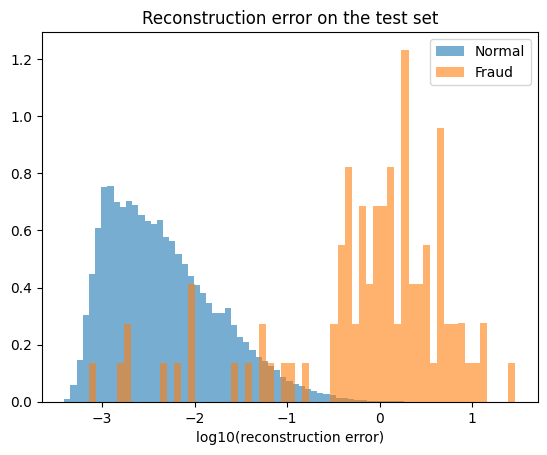

In [14]:
plt.hist(np.log10(test_scores[y_test == 0]), bins=60, alpha=0.6, density=True, label="Normal")
plt.hist(np.log10(test_scores[y_test == 1]), bins=60, alpha=0.6, density=True, label="Fraud")
plt.xlabel("log10(reconstruction error)")
plt.title("Reconstruction error on the test set")
plt.legend()
plt.show()

The reconstruction error is the fraud score. The overlap between the two curves explains the mistakes in the confusion matrix.

## 5. KNN with the elbow method

KNN is a supervised model: it predicts fraud based on the labels of the `k` nearest training transactions.

**Elbow method:** try many values of `k`, plot the error, and choose the `k` where the error stops improving much. The error is `1 - AUPRC` on the validation set (accuracy is not usable with this imbalance).

Chosen k: 5


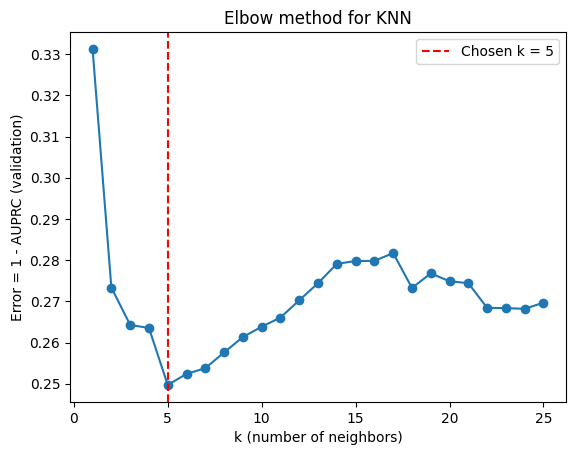

In [15]:
nn = NearestNeighbors(n_neighbors=25).fit(X_train)

_, val_idx = nn.kneighbors(X_val)
_, test_idx = nn.kneighbors(X_test)

val_labels = y_train[val_idx]
test_labels = y_train[test_idx]

errors = []
for k in range(1, 26):
    fraud_score = val_labels[:, :k].mean(axis=1)
    errors.append(1 - average_precision_score(y_val, fraud_score))

errors = np.array(errors)
best_k = int(np.argmax(errors <= errors.min() + 0.01)) + 1
print("Chosen k:", best_k)

plt.plot(range(1, 26), errors, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"Chosen k = {best_k}")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Error = 1 - AUPRC (validation)")
plt.title("Elbow method for KNN")
plt.legend()
plt.show()

The 25 nearest neighbors are found once and reused for every `k`. The fraud score of a transaction is the share of fraud among its `k` neighbors. The chosen `k` is the smallest one whose error is within 0.01 of the lowest error, which is where the curve flattens.

In [16]:
knn_results = evaluate(val_labels[:, :best_k].mean(axis=1), test_labels[:, :best_k].mean(axis=1))

AUPRC: 0.8150
ROC-AUC: 0.9262
Precision: 0.9506
Recall: 0.8105
F1: 0.8750

Confusion matrix (rows = actual, columns = predicted):
[[56647     4]
 [   18    77]]


KNN is evaluated the same way as the autoencoder: threshold chosen on the validation set, results reported on the test set.

## 6. Comparison and conclusion

,AUPRC,ROC-AUC,Precision,Recall,F1
Autoencoder,0.6001,0.9449,0.6353,0.5684,0.600
KNN (k=5),0.8150,0.9262,0.9506,0.8105,0.875


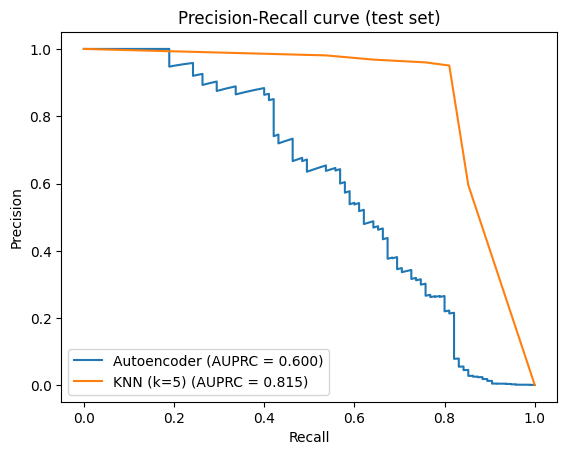

In [17]:
comparison = pd.DataFrame({"Autoencoder": ae_results, f"KNN (k={best_k})": knn_results}).T.round(4)
display(comparison)

for name, scores in [("Autoencoder", test_scores), (f"KNN (k={best_k})", test_labels[:, :best_k].mean(axis=1))]:
    p, r, _ = precision_recall_curve(y_test, scores)
    plt.plot(r, p, label=f"{name} (AUPRC = {average_precision_score(y_test, scores):.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve (test set)")
plt.legend()
plt.show()

In [18]:
print("Best model by AUPRC:", comparison["AUPRC"].idxmax())
for name, row in comparison.iterrows():
    print(f"{name}: catches {row['Recall'] * 100:.0f}% of frauds, "
          f"and {row['Precision'] * 100:.0f}% of its fraud alerts are real frauds")

Best model by AUPRC: KNN (k=5)
Autoencoder: catches 57% of frauds, and 64% of its fraud alerts are real frauds
KNN (k=5): catches 81% of frauds, and 95% of its fraud alerts are real frauds


### Conclusion

- The models are compared by AUPRC on the test set (printed above). Recall is the share of frauds caught, Precision is the share of alerts that are real frauds.
- **Results:** KNN (k=5) achieved the higher AUPRC (0.815 vs 0.600), with Precision 0.95 and Recall 0.81, compared with Precision 0.64 and Recall 0.57 for the autoencoder. The autoencoder still separates fraud well (ROC-AUC 0.945) without using any fraud labels.
- **Autoencoder:** it is trained on normal transactions only and never sees a fraud example. Its advantage is that it can flag new fraud patterns that were never labeled.
- **KNN:** supervised, it uses the fraud labels, which usually helps when labeled fraud examples are available.
- **Regularization:** Early Stopping was used, and Keras Tuner selected the best architecture and learning rate.
- **Tuning note:** the autoencoder was tuned by validation loss, which measures how well normal transactions are rebuilt, not how well fraud is detected. A lower reconstruction loss does not guarantee a better fraud score.
- **Limitation:** the test set has few frauds, so a small AUPRC difference between the models is not strong evidence that one is better.